<a href="https://colab.research.google.com/github/nitha604/news-article-categorisation/blob/main/04_modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install scikit-learn pandas numpy matplotlib seaborn -q

In [2]:
# ── Standard libraries ──────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import pickle
import os

# ── Visualisation ───────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# ── Feature extraction ──────────────────────────────────────────────────────
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

# ── Model selection / splitting ─────────────────────────────────────────────
from sklearn.model_selection import train_test_split

# ── Models ──────────────────────────────────────────────────────────────────
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

# ── Evaluation ──────────────────────────────────────────────────────────────
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# ── Misc ────────────────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

print(" All libraries imported successfully!")

 All libraries imported successfully!


In [3]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Load the cleaned dataset saved in Notebook 3
DATA_PATH   = '/content/drive/MyDrive/news_project/cleaned_data.csv'
PLOTS_PATH  = '/content/drive/MyDrive/news_project/plots'
MODELS_PATH = '/content/drive/MyDrive/news_project/models'

# Make sure output directories exist
os.makedirs(PLOTS_PATH,  exist_ok=True)
os.makedirs(MODELS_PATH, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape  : {df.shape}")
print(f"Columns        : {list(df.columns)}")
print(f"Category counts:\n{df['category'].value_counts()}")
df.head(3)

Mounted at /content/drive
Dataset shape  : (2040, 3)
Columns        : ['text', 'category', 'clean_text']
Category counts:
category
Sports        1000
Technology    1000
Education       20
Politics        20
Name: count, dtype: int64


,text,category,clean_text
0,Barrera outslugs Morales for title Somehow Mar...,Sports,barrera outslug morale title somehow marco ant...
1,Ajax finally comes to terms with Trabelsi Amst...,Sports,ajax finally come term trabelsi amsterdam neth...
2,Steelers' Burress to Miss Game With Jets (AP) ...,Sports,steeler burress miss game jet ap ap pittsburgh...


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

# --- Label encode the target column ---
le = LabelEncoder()
y  = le.fit_transform(df['category'])
print("Classes (alphabetical):", le.classes_)
# Mapping: 0=Education, 1=Politics, 2=Sports, 3=Technology  (depends on your data)

# --- TF-IDF vectorisation ---
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X = vectorizer.fit_transform(df['clean_text'])

print(f"\nTF-IDF matrix shape : {X.shape}")
print(f"  → {X.shape[0]} articles  ×  {X.shape[1]} features")
print("\nSample features (first 15):", vectorizer.get_feature_names_out()[:15])

Classes (alphabetical): ['Education' 'Politics' 'Sports' 'Technology']

TF-IDF matrix shape : (2040, 5000)
  → 2040 articles  ×  5000 features

Sample features (first 15): ['aaron' 'aaron peirsol' 'aaron rodger' 'abandon' 'abc' 'ability' 'able'
 'able take' 'aboard' 'aboard international' 'abound' 'abraham' 'abroad'
 'abuse' 'ac']


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train : {X_train.shape[0]} samples")
print(f"Test  : {X_test.shape[0]}  samples")

# Verify stratification
unique, train_counts = np.unique(y_train, return_counts=True)
_,      test_counts  = np.unique(y_test,  return_counts=True)

print("\nTrain distribution:", dict(zip(le.classes_, train_counts)))
print("Test  distribution:", dict(zip(le.classes_, test_counts)))
print("\n Class ratios look balanced — stratification worked!")

Train : 1632 samples
Test  : 408  samples

Train distribution: {'Education': np.int64(16), 'Politics': np.int64(16), 'Sports': np.int64(800), 'Technology': np.int64(800)}
Test  distribution: {'Education': np.int64(4), 'Politics': np.int64(4), 'Sports': np.int64(200), 'Technology': np.int64(200)}

 Class ratios look balanced — stratification worked!


In [6]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

print("=" * 55)
print("          MODEL 1: Naive Bayes (MultinomialNB)")
print("=" * 55)

nb_model = MultinomialNB(alpha=0.1)   # alpha is Laplace smoothing
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

print(classification_report(y_test, y_pred_nb, target_names=le.classes_))
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred_nb)*100:.2f}%")

          MODEL 1: Naive Bayes (MultinomialNB)
              precision    recall  f1-score   support

   Education       0.00      0.00      0.00         4
    Politics       0.00      0.00      0.00         4
      Sports       0.97      0.98      0.97       200
  Technology       0.95      0.97      0.96       200

    accuracy                           0.96       408
   macro avg       0.48      0.49      0.48       408
weighted avg       0.94      0.96      0.95       408

Overall Accuracy: 95.83%


In [7]:
from sklearn.linear_model import LogisticRegression

print("=" * 55)
print("       MODEL 2: Logistic Regression (OvR)")
print("=" * 55)

lr_model = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print(classification_report(y_test, y_pred_lr, target_names=le.classes_))
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred_lr)*100:.2f}%")

# ── Top 5 words per class ────────────────────────────────────────────────────
print("\n Top 5 most informative words per class:")
feature_names = vectorizer.get_feature_names_out()
for class_idx, class_name in enumerate(le.classes_):
    top5_indices = np.argsort(lr_model.coef_[class_idx])[-5:][::-1]
    top5_words   = [feature_names[i] for i in top5_indices]
    print(f"  {class_name:12s}: {top5_words}")

       MODEL 2: Logistic Regression (OvR)
              precision    recall  f1-score   support

   Education       0.00      0.00      0.00         4
    Politics       0.00      0.00      0.00         4
      Sports       0.95      0.98      0.97       200
  Technology       0.96      0.96      0.96       200

    accuracy                           0.95       408
   macro avg       0.48      0.49      0.48       408
weighted avg       0.93      0.95      0.94       408

Overall Accuracy: 95.34%

 Top 5 most informative words per class:
  Education   : ['class', 'school', 'registration', 'exam', 'student']
  Politics    : ['election', 'nda', 'congress', 'political', 'crisis']
  Sports      : ['team', 'season', 'win', 'cup', 'victory']
  Technology  : ['microsoft', 'internet', 'company', 'space', 'software']


In [8]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

print("=" * 55)
print("          MODEL 3: SVM (LinearSVC + Calibrated)")
print("=" * 55)

# Wrap LinearSVC so it can output probabilities
svm_base  = LinearSVC(max_iter=2000, C=1.0, random_state=42)
svm_model = CalibratedClassifierCV(svm_base, cv=5)
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print(classification_report(y_test, y_pred_svm, target_names=le.classes_))
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred_svm)*100:.2f}%")

          MODEL 3: SVM (LinearSVC + Calibrated)
              precision    recall  f1-score   support

   Education       1.00      0.25      0.40         4
    Politics       0.50      0.50      0.50         4
      Sports       0.97      0.98      0.98       200
  Technology       0.97      0.97      0.97       200

    accuracy                           0.97       408
   macro avg       0.86      0.68      0.71       408
weighted avg       0.97      0.97      0.96       408

Overall Accuracy: 96.57%


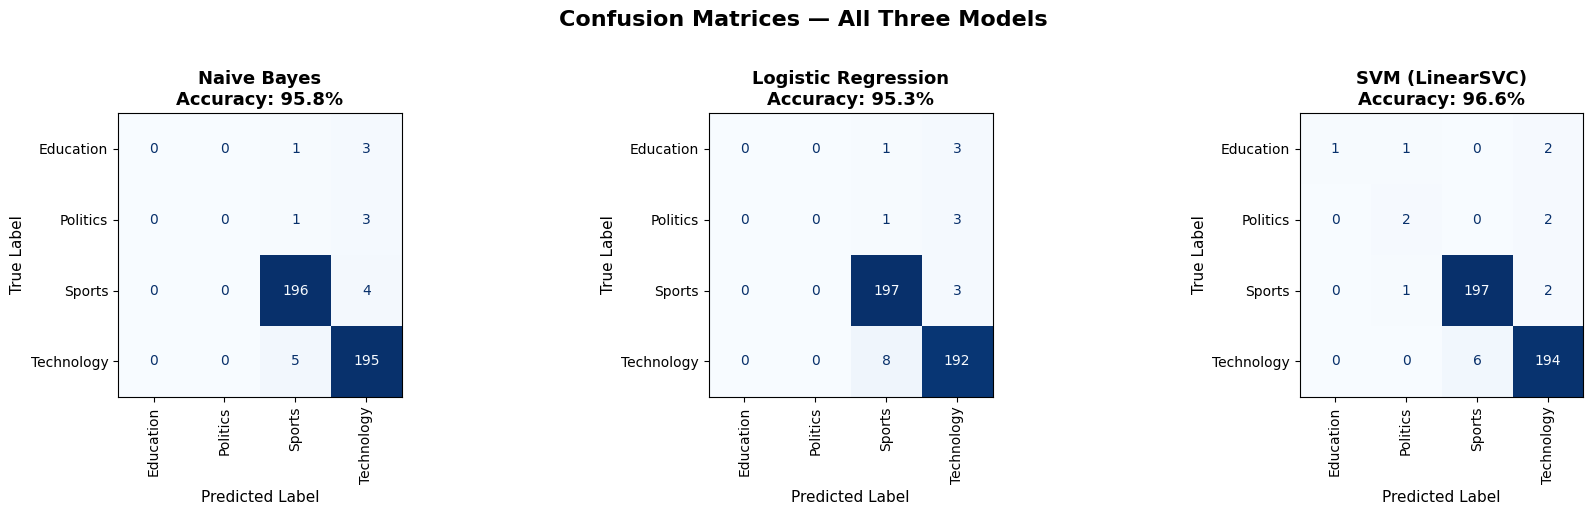

 Confusion matrices saved → /content/drive/MyDrive/news_project/plots/confusion_matrices.png


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrices — All Three Models', fontsize=16, fontweight='bold', y=1.02)

models_info = [
    ('Naive Bayes',        y_pred_nb),
    ('Logistic Regression', y_pred_lr),
    ('SVM (LinearSVC)',     y_pred_svm),
]

for ax, (model_name, y_pred) in zip(axes, models_info):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=le.classes_
    )
    disp.plot(
        ax=ax,
        colorbar=False,
        cmap='Blues',
        xticks_rotation='vertical'
    )
    acc = accuracy_score(y_test, y_pred) * 100
    ax.set_title(f'{model_name}\nAccuracy: {acc:.1f}%', fontsize=13, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('True Label', fontsize=11)

plt.tight_layout()

cm_save_path = f'{PLOTS_PATH}/confusion_matrices.png'
plt.savefig(cm_save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f" Confusion matrices saved → {cm_save_path}")


 Model Comparison:
| Model               |   Accuracy (%) |   Precision (%) |   Recall (%) |   F1 Score (%) |
|:--------------------|---------------:|----------------:|-------------:|---------------:|
| Naive Bayes         |          95.83 |           47.92 |        48.88 |          48.39 |
| Logistic Regression |          95.34 |           47.67 |        48.62 |          48.14 |
| SVM (LinearSVC)     |          96.57 |           86.01 |        67.62 |          71.19 |

 Results saved → /content/drive/MyDrive/news_project/model_results.csv


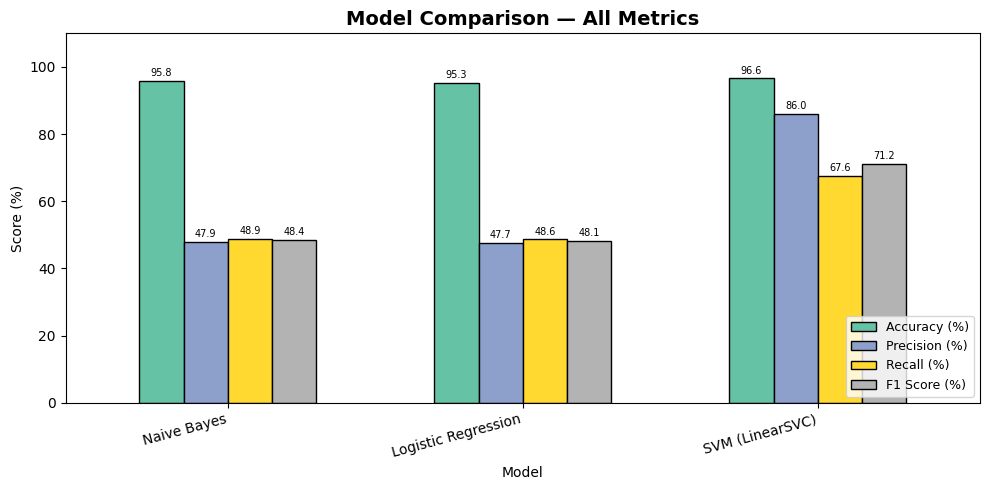

 Bar chart saved → /content/drive/MyDrive/news_project/plots/model_comparison_bar.png


In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def get_metrics(y_true, y_pred, name):
    return {
        'Model':           name,
        'Accuracy (%)':    round(accuracy_score(y_true, y_pred) * 100, 2),
        'Precision (%)':   round(precision_score(y_true, y_pred, average='macro') * 100, 2),
        'Recall (%)':      round(recall_score(y_true, y_pred,    average='macro') * 100, 2),
        'F1 Score (%)':    round(f1_score(y_true, y_pred,        average='macro') * 100, 2),
    }

results = pd.DataFrame([
    get_metrics(y_test, y_pred_nb,  "Naive Bayes"),
    get_metrics(y_test, y_pred_lr,  "Logistic Regression"),
    get_metrics(y_test, y_pred_svm, "SVM (LinearSVC)"),
]).set_index('Model')

print("\n Model Comparison:")
try:
    print(results.to_markdown())
except ImportError:
    print(results.to_string())

# Save results CSV to Drive
results_csv_path = '/content/drive/MyDrive/news_project/model_results.csv'
results.to_csv(results_csv_path)
print(f"\n Results saved → {results_csv_path}")

# Visualise the comparison
ax = results.plot(kind='bar', figsize=(10, 5), colormap='Set2', edgecolor='black', width=0.6)
ax.set_title('Model Comparison — All Metrics', fontsize=14, fontweight='bold')
ax.set_ylabel('Score (%)')
ax.set_ylim(0, 110)
ax.set_xticklabels(results.index, rotation=15, ha='right')
ax.legend(loc='lower right', fontsize=9)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', fontsize=7, padding=2)
plt.tight_layout()
bar_save_path = f'{PLOTS_PATH}/model_comparison_bar.png'
plt.savefig(bar_save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f" Bar chart saved → {bar_save_path}")

In [11]:
import pickle

def save_pickle(obj, filename):
    # Save in models/ subfolder
    path = f'{MODELS_PATH}/{filename}'
    with open(path, 'wb') as f:
        pickle.dump(obj, f)
    # Also save directly in news_project/ for convenient loading in Notebook 5
    parent_path = f'/content/drive/MyDrive/news_project/{filename}'
    with open(parent_path, 'wb') as f:
        pickle.dump(obj, f)
    print(f"   Saved: {filename}")

print("Saving all models and artefacts...")
save_pickle(nb_model,    'nb_model.pkl')
save_pickle(lr_model,    'lr_model.pkl')
save_pickle(svm_model,   'svm_model.pkl')
save_pickle(vectorizer,  'vectorizer.pkl')
save_pickle(vectorizer,  'tfidf_vectorizer.pkl')
save_pickle(le,          'label_encoder.pkl')

# Also record which model was best
best_model_name = results['F1 Score (%)'].idxmax()
print(f"\n Best model by macro F1: {best_model_name}")

best_model_map = {
    'Naive Bayes':         nb_model,
    'Logistic Regression': lr_model,
    'SVM (LinearSVC)':     svm_model,
}
save_pickle(best_model_map[best_model_name], 'best_model.pkl')
print(f"\n Best model also saved as best_model.pkl → ready for Notebook 5!")

Saving all models and artefacts...
   Saved: nb_model.pkl
   Saved: lr_model.pkl
   Saved: svm_model.pkl
   Saved: vectorizer.pkl
   Saved: tfidf_vectorizer.pkl
   Saved: label_encoder.pkl

 Best model by macro F1: SVM (LinearSVC)
   Saved: best_model.pkl

 Best model also saved as best_model.pkl → ready for Notebook 5!


 Detailed Classification Report — SVM (LinearSVC)
              precision    recall  f1-score   support

   Education       1.00      0.25      0.40         4
    Politics       0.50      0.50      0.50         4
      Sports       0.97      0.98      0.98       200
  Technology       0.97      0.97      0.97       200

    accuracy                           0.97       408
   macro avg       0.86      0.68      0.71       408
weighted avg       0.97      0.97      0.96       408



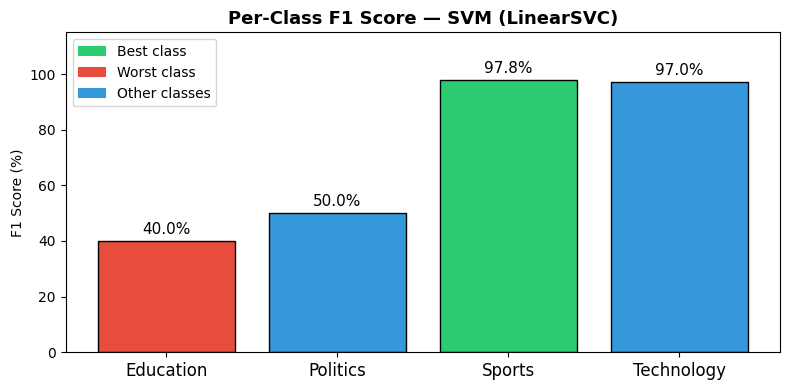


 Best  class : Sports        F1 = 97.8%
  Worst class : Education     F1 = 40.0%

 Tip: If 'Education' performs poorly, consider:
   - Collecting more training samples for that class
   - Adding class_weight='balanced' to handle imbalance

 Per-class chart saved → /content/drive/MyDrive/news_project/plots/per_class_f1.png


In [12]:
# Use the best model identified above
best_preds = best_model_map[best_model_name].predict(X_test)

print(f" Detailed Classification Report — {best_model_name}")
print("=" * 55)
report = classification_report(
    y_test, best_preds,
    target_names=le.classes_,
    output_dict=True
)
print(classification_report(y_test, best_preds, target_names=le.classes_))

# ── Per-class F1 bar chart ───────────────────────────────────────────────────
class_f1  = {cls: report[cls]['f1-score'] for cls in le.classes_}
colours   = ['#e74c3c' if v == min(class_f1.values()) else
             '#2ecc71' if v == max(class_f1.values()) else
             '#3498db' for v in class_f1.values()]

plt.figure(figsize=(8, 4))
bars = plt.bar(class_f1.keys(), [v * 100 for v in class_f1.values()],
               color=colours, edgecolor='black')
plt.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=11)
plt.title(f'Per-Class F1 Score — {best_model_name}', fontsize=13, fontweight='bold')
plt.ylabel('F1 Score (%)')
plt.ylim(0, 115)
plt.xticks(fontsize=12)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2ecc71', label='Best class  '),
    Patch(facecolor='#e74c3c', label='Worst class '),
    Patch(facecolor='#3498db', label='Other classes'),
]
plt.legend(handles=legend_elements, fontsize=10)
plt.tight_layout()
perclass_save_path = f'{PLOTS_PATH}/per_class_f1.png'
plt.savefig(perclass_save_path, dpi=150, bbox_inches='tight')
plt.show()

# ── Summary ─────────────────────────────────────────────────────────────────
best_class  = max(class_f1, key=class_f1.get)
worst_class = min(class_f1, key=class_f1.get)

print(f"\n Best  class : {best_class:12s}  F1 = {class_f1[best_class]*100:.1f}%")
print(f"  Worst class : {worst_class:12s}  F1 = {class_f1[worst_class]*100:.1f}%")
print(f"\n Tip: If '{worst_class}' performs poorly, consider:")
print("   - Collecting more training samples for that class")
print("   - Adding class_weight='balanced' to handle imbalance")
print(f"\n Per-class chart saved → {perclass_save_path}")